# 1113 이동현

# 교과서에서 전처리·탐색한 `weather2023.xlsx`를 이용하여  
기온(temp), 풍속(wind), 습도(humi), 전운량(cloud)으로  
합계 일조시간(sunshine)을 예측하는 선형회귀 모델을 만드는 실습이다.

<탐구질문> 오늘의 기온, 풍속,습도, 전운량을 알면 일조시간을 예측할 수 있을까?

STEP 1. 라이브러리 불러오기와 데이터 확인, 데이터 전처리


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

data_path = Path('../데이터파일/weather2023.xlsx')
if not data_path.exists():
    data_path = Path('데이터파일/weather2023.xlsx')
weather = pd.read_excel(data_path, index_col='date')
weather.drop(['rain','location','loc_name'],axis=1,inplace=True)
weather.head()

,temp,wind,humi,sunshine,cloud
date,,,,,
2023-01-01,-0.2,2.7,55.0,9.0,1.3
2023-01-02,-4.5,2.5,46.0,9.1,0.0
2023-01-03,-5.0,1.8,49.0,9.1,0.0
2023-01-04,-1.8,1.9,51.0,8.7,1.9
2023-01-05,-1.6,1.6,58.1,4.7,3.6


STEP 2-1. 특성변수 후보와 목표변수의 관계 시각화하기(1)

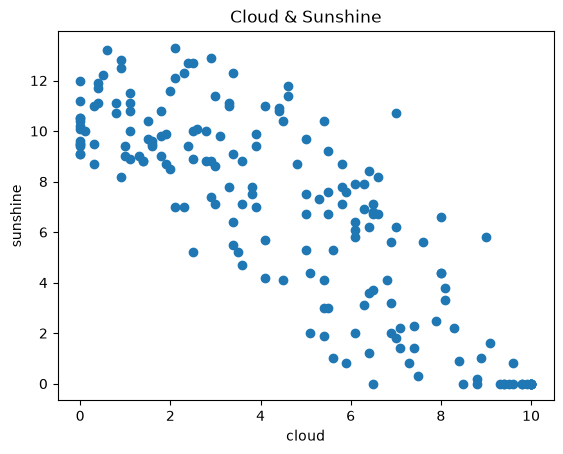

In [2]:
#시각화 코드(1): 구름양과 일조량, 산점도
plt.scatter(x=weather['cloud'],y=weather['sunshine'])
plt.xlabel('cloud')
plt.ylabel('sunshine')
plt.title('Cloud & Sunshine')
plt.show()

STEP 2-2. 특성변수 후보와 목표변수의 관계 시각화하기(2)


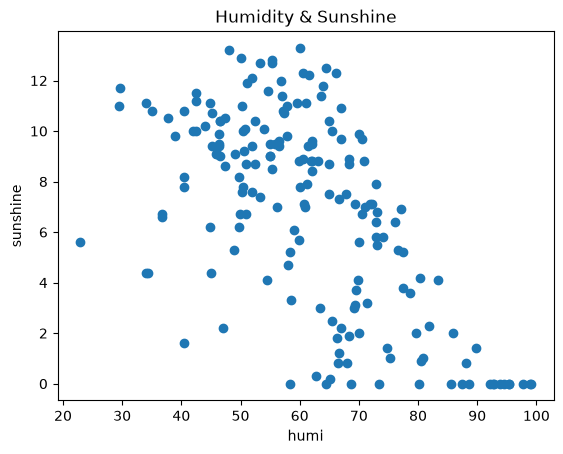

In [3]:
#시각화 코드(2): 습도와 일조량, 산점도
plt.scatter(x=weather['humi'],y=weather['sunshine'])
plt.xlabel('humi')
plt.ylabel('sunshine')
plt.title('Humidity & Sunshine')
plt.show()

STEP3. 입력 데이터 X와 정답 y 정하기

In [4]:
X, Y = weather[['cloud', 'wind', 'humi', 'temp']], weather['sunshine']
print(X.head())
print(Y.head())

            cloud  wind  humi  temp
date                               
2023-01-01    1.3   2.7  55.0  -0.2
2023-01-02    0.0   2.5  46.0  -4.5
2023-01-03    0.0   1.8  49.0  -5.0
2023-01-04    1.9   1.9  51.0  -1.8
2023-01-05    3.6   1.6  58.1  -1.6
date
2023-01-01    9.0
2023-01-02    9.1
2023-01-03    9.1
2023-01-04    8.7
2023-01-05    4.7
Name: sunshine, dtype: float64


STEP4. 훈련데이터와 테스트테이터로 분리하기

In [5]:
%pip install scikit-learn

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print("훈련 데이터:", X_train.shape, y_train.shape)
print("테스트 데이터:", X_test.shape, y_test.shape)


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
훈련 데이터: (144, 4) (144,)
테스트 데이터: (37, 4) (37,)


STEP5. 모델1: 선형회귀 모델 학습하기

In [6]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-1.04, 0.2 ,-0.06, 0.12]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['cloud','wind','humi','temp']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,13.48
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


STEP6. 모델1: 테스트 데이터 예측하기

In [7]:
pred = model.predict(X_test)
result = pd.DataFrame({'original_index':y_test.index, 'actual':y_test.values, 'predicted':pred})
print(result.head(10))

  original_index  actual  predicted
0     2023-01-20     8.7  10.220608
1     2023-02-12     2.0   2.696020
2     2023-06-03    13.3  10.724790
3     2023-03-20    10.0   8.865658
4     2023-05-26    10.7   5.592091
5     2023-01-16     8.8   6.580402
6     2023-01-25     9.4   8.029100
7     2023-03-10     9.6  11.635115
8     2023-04-24     7.8   7.349061
9     2023-04-29     0.8   0.118703


STEP7. 모델1: 성능 평가하기

In [8]:
from sklearn.metrics import mean_absolute_error, r2_score

mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)

print("선형회귀 MAE: ", mae)
print("선형회귀 R2: ", r2)

선형회귀 MAE:  1.4872732719755144
선형회귀 R2:  0.7737787722337529


STEP8. 모델2: 랜덤포레스트 학습, 예측, 성능평가 (STEP5~7 모델명만 바꿔서 학습)

In [9]:
from sklearn.ensemble import RandomForestRegressor

# 1. 랜덤 포레스트 회귀 모델 학습하기
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# 2. 테스트 데이터 예측하기
rf_pred = rf_model.predict(X_test)

# 3. 랜덤포레스트 모델 평가
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("랜덤포레스트 MAE: ", rf_mae)
print("랜덤포레스트 R2: ", rf_r2)

랜덤포레스트 MAE:  1.3959999999999988
랜덤포레스트 R2:  0.7915663657501892


STEP9. 모델1과 모델2: 성능비교

In [10]:
print("선형회귀 MAE: ", mae)
print("선형회귀 R2: ", r2)

print("랜덤포레스트 MAE: ", rf_mae)
print("랜덤포레스트 R2: ", rf_r2)

선형회귀 MAE:  1.4872732719755144
선형회귀 R2:  0.7737787722337529
랜덤포레스트 MAE:  1.3959999999999988
랜덤포레스트 R2:  0.7915663657501892


STEP10. 성능 평가 결과로 모델 선정, 실제값과 예측값 시각화하기

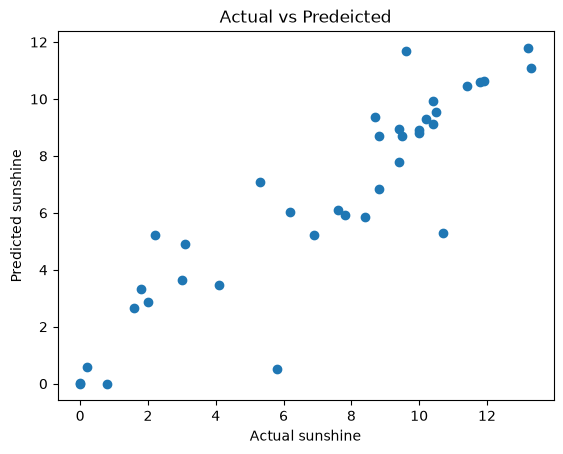

In [11]:
plt.scatter(y_test, rf_pred)
plt.xlabel("Actual sunshine")
plt.ylabel("Predicted sunshine")
plt.title("Actual vs Predeicted")
plt.show()

STEP 11. 새로운 날씨 데이터 예측하기
 - X값 중 하나 이상을 바꾸어 새로운 날씨의 일조 시간 예측

In [12]:
new_weather = pd.DataFrame({
    "temp": [20.0],
    "wind": [2.5],
    "humi": [60.0],
    "cloud": [4.0]
})

# 학습할 때 사용한 특성의 순서에 맞추기
new_weather = new_weather.loc[:, rf_model.feature_names_in_]
new_pred = rf_model.predict(new_weather)

print("예측 일조시간: ", new_pred[0])

예측 일조시간:  9.572000000000003


<회귀 모델 성능지표 해석>

MAE: 작을수록 좋음 (실제값과 예측값이 평균적으로 얼마나 차이 나는지?)

R²: 1에 가까울수록 좋음 (모델이 실제 데이터의 변화를 얼마나 잘 설명하는지?)